# Movie Success Patterns: Genre, Cast, Crew, Keywords, and Release Month

**Course project notebook**  
**Team members:** Add names and roll numbers before submission  
**Topic uniqueness:** Confirm with the instructor/class list before submission  
**Dataset:** `TMDB  IMDB Movies Dataset.csv` (443,147 source rows)

This notebook studies frequent combinations associated with high IMDb ratings and a revenue-to-budget success proxy. It compares eight frequent-itemset approaches and evaluates a decision tree and Bernoulli Naive Bayes classifier.


## 1. Research question and scope

**Research question:** Which combinations of genre, director, lead cast, keywords, and release month occur more often among successful movies than the relevant base rate?

The primary success outcome is **high IMDb rating**: `averageRating >= 7.0`, among released titles with at least 100 IMDb votes. The secondary outcome is **reported revenue greater than reported budget**, among released titles with positive values for both fields. The latter is a rough proxy; it does not account for marketing, distribution, inflation, or whether the financial figures are complete.

Association-rule lift is interpreted as `P(outcome | pattern) / P(outcome)`. Lift above 1 indicates an association in this dataset; it does not establish causation or a guaranteed recipe for success.


In [1]:
from pathlib import Path
from collections import Counter
import math
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg", force=True)
import matplotlib.pyplot as plt
import seaborn as sns
from io import BytesIO
from IPython.display import Image, display

from movie_mining import (
    VerticalTransactionDB,
    mine_apriori,
    mine_hash_apriori,
    mine_eclat,
    mine_fp_growth,
    mine_partitioned_apriori,
    mine_dic_checkpoint,
    mine_aclose,
    mine_pincer,
    make_outcome_rules,
)

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_SEED = 42
DATA_PATH = Path("TMDB  IMDB Movies Dataset.csv")
if not DATA_PATH.exists():
    candidates = list(Path.cwd().glob("TMDB*Movies*Dataset.csv"))
    if not candidates:
        raise FileNotFoundError("Place the supplied movie CSV beside this notebook.")
    DATA_PATH = candidates[0]
print(f"Dataset: {DATA_PATH.resolve()}")

def show_figure(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=140, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(fig)


Dataset: D:\Semester 7\Big Data\Project\TMDB  IMDB Movies Dataset.csv


## 2. Load and audit the data

Only the columns needed for the project are loaded. Duplicate TMDB IDs are resolved by retaining the row with the most complete project metadata, then the largest IMDb vote count, then the largest TMDB vote count. This deterministic rule keeps one transaction per TMDB ID; it may not resolve every source-link ambiguity, so duplicate counts are reported.


In [2]:
USECOLS = [
    "id", "title", "vote_average", "vote_count", "status", "release_date",
    "revenue", "budget", "tconst", "genres", "keywords", "directors",
    "averageRating", "numVotes", "cast",
]
movies = pd.read_csv(DATA_PATH, usecols=USECOLS, low_memory=False)
source_rows = len(movies)
for column in ["vote_average", "vote_count", "revenue", "budget", "averageRating", "numVotes"]:
    movies[column] = pd.to_numeric(movies[column], errors="coerce")
movies["release_date"] = pd.to_datetime(movies["release_date"], errors="coerce")
movies["metadata_completeness"] = movies[["genres", "directors", "cast", "keywords", "release_date"]].notna().sum(axis=1)
duplicate_tmdb_rows = int(movies["id"].duplicated(keep=False).sum())
duplicate_tmdb_excess = int(movies["id"].duplicated().sum())
movies = (
    movies.sort_values(
        ["metadata_completeness", "numVotes", "vote_count"],
        ascending=[False, False, False],
        na_position="last",
    )
    .drop_duplicates(subset="id", keep="first")
    .copy()
)
deduplicated_rows = len(movies)
current_date = pd.Timestamp.today().normalize()
released = movies.loc[
    movies["status"].eq("Released")
    & movies["release_date"].notna()
    & movies["release_date"].le(current_date)
].copy()

profile = pd.DataFrame({
    "value": [source_rows, duplicate_tmdb_excess, deduplicated_rows, len(released)],
}, index=["Source rows", "Duplicate TMDB-ID rows removed", "Unique TMDB-ID rows retained", "Released titles with a usable date"])
display(profile)
missing_profile = pd.DataFrame({
    "missing_rows": released[["genres", "directors", "cast", "keywords", "release_date"]].isna().sum(),
})
missing_profile["missing_percent"] = (100 * missing_profile["missing_rows"] / len(released)).round(1)
display(missing_profile.sort_values("missing_percent", ascending=False))
display(released[["title", "release_date", "genres", "directors", "cast", "averageRating", "numVotes", "revenue", "budget"]].head(5))


,value
Source rows,443147
Duplicate TMDB-ID rows removed,13448
Unique TMDB-ID rows retained,429699
Released titles with a usable date,409984


,missing_rows,missing_percent
keywords,242751,59.2
genres,62356,15.2
cast,58987,14.4
directors,9045,2.2
release_date,0,0.0


,title,release_date,genres,directors,cast,averageRating,numVotes,revenue,budget
14,The Shawshank Redemption,1994-09-23,"Drama, Crime",Frank Darabont,"Tim Robbins, Morgan Freeman, Bob Gunton, William Sadler, Clancy Brown, Gil Bellows, James Whitmo...",9.3,3256153,28341469,25000000
2,The Dark Knight,2008-07-16,"Drama, Action, Crime, Thriller",Christopher Nolan,"Christian Bale, Heath Ledger, Aaron Eckhart, Michael Caine, Maggie Gyllenhaal, Gary Oldman, Morg...",9.1,3242393,1004558444,185000000
0,Inception,2010-07-15,"Action, Science Fiction, Adventure",Christopher Nolan,"Leonardo DiCaprio, Joseph Gordon-Levitt, Ken Watanabe, Tom Hardy, Elliot Page, Dileep Rao, Cilli...",8.8,2882270,825532764,160000000
7,Fight Club,1999-10-15,Drama,David Fincher,"Edward Norton, Brad Pitt, Helena Bonham Carter, Meat Loaf, Jared Leto, Zach Grenier, Holt McCall...",8.8,2675712,100853753,63000000
1,Interstellar,2014-11-05,"Adventure, Drama, Science Fiction",Christopher Nolan,"Matthew McConaughey, Anne Hathaway, Michael Caine, Jessica Chastain, Casey Affleck, Wes Bentley,...",8.7,2624268,701729206,165000000


### Data-quality decisions

The source contains repeated IDs, incomplete keywords/cast/genre fields, and unreleased or future-dated titles. The analysis uses released titles with a usable release date and deduplicates by TMDB ID. Missing attributes are left absent from the basket rather than treated as a literal category. The effective sample size is shown for each target so missing revenue is never mislabeled as a box-office failure.


In [3]:
rating_data = released.loc[
    released["averageRating"].notna()
    & released["numVotes"].ge(100)
].copy()
rating_data["high_rating"] = rating_data["averageRating"].ge(7.0)

box_data = released.loc[
    released["revenue"].gt(0)
    & released["budget"].gt(0)
].copy()
box_data["box_hit"] = box_data["revenue"].gt(box_data["budget"])

target_summary = pd.DataFrame([
    {"target": "High IMDb rating (>=7; >=100 votes)", "eligible_titles": len(rating_data), "positive_titles": int(rating_data["high_rating"].sum()), "base_rate": rating_data["high_rating"].mean()},
    {"target": "Revenue > budget (proxy)", "eligible_titles": len(box_data), "positive_titles": int(box_data["box_hit"].sum()), "base_rate": box_data["box_hit"].mean()},
])
target_summary["base_rate_percent"] = (100 * target_summary.pop("base_rate")).round(1)
display(target_summary)


,target,eligible_titles,positive_titles,base_rate_percent
0,High IMDb rating (>=7; >=100 votes),177269,40054,22.6
1,Revenue > budget (proxy),10119,6586,65.1


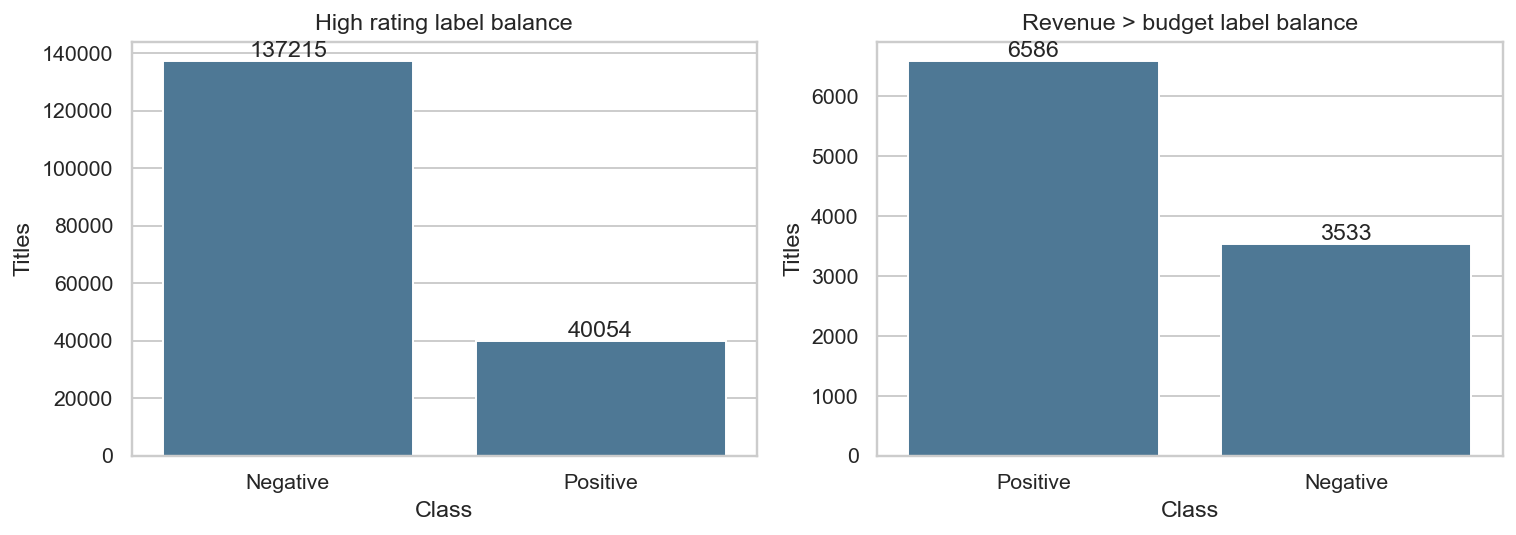

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, frame, column, title in [
    (axes[0], rating_data, "high_rating", "High rating label balance"),
    (axes[1], box_data, "box_hit", "Revenue > budget label balance"),
]:
    counts = frame[column].map({True: "Positive", False: "Negative"}).value_counts()
    sns.barplot(x=counts.index, y=counts.values, ax=ax, color="#427AA1")
    ax.set(title=title, xlabel="Class", ylabel="Titles")
    for container in ax.containers:
        ax.bar_label(container, fmt="%d")
plt.tight_layout()
show_figure(fig)


## 3. Convert each movie into a transaction

Each basket contains typed items so that a genre cannot be confused with an actor or keyword. The cast is limited to the first three credited names; keywords are limited to the first eight. The release month is included. Each mining basket receives exactly one outcome item.


In [5]:
def _split_field(value, prefix, limit=None):
    if value is None or pd.isna(value):
        return []
    values = [part.strip() for part in str(value).split(",") if part.strip()]
    if limit is not None:
        values = values[:limit]
    return [f"{prefix}{value.casefold()}" for value in values]

def feature_items(genres, directors, cast, keywords, release_date):
    items = []
    items.extend(_split_field(genres, "GENRE::"))
    items.extend(_split_field(directors, "DIRECTOR::"))
    items.extend(_split_field(cast, "ACTOR::", limit=3))
    items.extend(_split_field(keywords, "KEYWORD::", limit=8))
    if pd.notna(release_date):
        items.append(f"MONTH::{release_date.month:02d}")
    return sorted(set(items))

def feature_baskets(frame):
    fields = ["genres", "directors", "cast", "keywords", "release_date"]
    return [feature_items(*row) for row in frame[fields].itertuples(index=False, name=None)]

def outcome_baskets(frame, target_column, positive_name, negative_name):
    baskets = feature_baskets(frame)
    labels = frame[target_column].to_numpy(dtype=bool)
    for basket, label in zip(baskets, labels):
        basket.append("OUTCOME::" + (positive_name if label else negative_name))
    return baskets

example_baskets = outcome_baskets(rating_data.head(3), "high_rating", "HighRating", "OtherRating")
for title, basket in zip(rating_data["title"].head(3), example_baskets):
    print(title, "->", basket[:12], "...")


The Shawshank Redemption -> ['ACTOR::bob gunton', 'ACTOR::morgan freeman', 'ACTOR::tim robbins', 'DIRECTOR::frank darabont', 'GENRE::crime', 'GENRE::drama', 'KEYWORD::based on novel or book', 'KEYWORD::corruption', 'KEYWORD::delinquent', 'KEYWORD::friendship', 'KEYWORD::hope', 'KEYWORD::police brutality'] ...
The Dark Knight -> ['ACTOR::aaron eckhart', 'ACTOR::christian bale', 'ACTOR::heath ledger', 'DIRECTOR::christopher nolan', 'GENRE::action', 'GENRE::crime', 'GENRE::drama', 'GENRE::thriller', 'KEYWORD::anti hero', 'KEYWORD::chaos', 'KEYWORD::crime fighter', 'KEYWORD::joker'] ...
Inception -> ['ACTOR::joseph gordon-levitt', 'ACTOR::ken watanabe', 'ACTOR::leonardo dicaprio', 'DIRECTOR::christopher nolan', 'GENRE::action', 'GENRE::adventure', 'GENRE::science fiction', 'KEYWORD::airplane', 'KEYWORD::dream', 'KEYWORD::france', 'KEYWORD::kidnapping', 'KEYWORD::mission'] ...


## 4. Frequent-itemset algorithms

The comparison includes the class baselines (Apriori and FP-Growth) and the requested variants: hash-based Apriori, vertical ECLAT, partitioning Apriori, dynamic checkpoint candidate discovery, A-Close closure filtering, and bounded Pincer-style maximal mining.

All algorithms receive the same full eligible rating transaction database, support threshold, and maximum pattern length. The notebook reports each method's output type: all frequent sets, closed sets, or maximal sets. DIC and Pincer are explicitly identified as bounded teaching implementations in the source and report; their timings are not a claim of parity with optimized research implementations.


In [6]:
mining_frame = rating_data.copy()
raw_mining_baskets = outcome_baskets(mining_frame, "high_rating", "HighRating", "OtherRating")

# Keep a balanced, interpretable vocabulary: all observed genres/months and
# the most common directors, actors, and keywords from the full eligible set.
item_counts = Counter(item for basket in raw_mining_baskets for item in basket)
category_limits = {"GENRE::": 30, "DIRECTOR::": 20, "ACTOR::": 30, "KEYWORD::": 40, "MONTH::": 12}
vocabulary = set()
for prefix, limit in category_limits.items():
    category_items = [item for item in item_counts if item.startswith(prefix)]
    if prefix in {"GENRE::", "MONTH::"}:
        vocabulary.update(category_items)
    else:
        vocabulary.update(sorted(category_items, key=lambda item: (-item_counts[item], item))[:limit])
vocabulary.update(item for item in item_counts if item.startswith("OUTCOME::"))
mining_baskets = [sorted(set(basket) & vocabulary) for basket in raw_mining_baskets]
mining_db = VerticalTransactionDB(mining_baskets)
MIN_SUPPORT = 0.0015
MAX_LEN = 4
MIN_COUNT = math.ceil(len(mining_baskets) * MIN_SUPPORT)
print(f"Mining transactions: {len(mining_baskets):,}; vocabulary: {len(vocabulary):,}; minimum support count: {MIN_COUNT}; max itemset length: {MAX_LEN}")
print("High-rating base rate in mining database:", round(mining_frame["high_rating"].mean(), 4))


Mining transactions: 177,269; vocabulary: 123; minimum support count: 266; max itemset length: 4
High-rating base rate in mining database: 0.226


In [7]:
apriori_result = mine_apriori(mining_db, min_support=MIN_SUPPORT, max_len=MAX_LEN)
print("Apriori patterns:", len(apriori_result["patterns"]), "candidates:", apriori_result["candidate_count"], "seconds:", round(apriori_result["seconds"], 3))


Apriori patterns: 1990 candidates: 7104 seconds: 0.065


In [8]:
fp_result = mine_fp_growth(mining_db, min_support=MIN_SUPPORT, max_len=MAX_LEN)
print("FP-Growth patterns:", len(fp_result["patterns"]), "nodes visited:", fp_result["candidate_count"], "seconds:", round(fp_result["seconds"], 3))


FP-Growth patterns: 1990 nodes visited: 1990 seconds: 0.819


In [9]:
hash_result = mine_hash_apriori(mining_db, min_support=MIN_SUPPORT, max_len=MAX_LEN, bucket_count=2048)
print("Hash Apriori patterns:", len(hash_result["patterns"]), "candidates:", hash_result["candidate_count"], "seconds:", round(hash_result["seconds"], 3))


Hash Apriori patterns: 1990 candidates: 5387 seconds: 0.293


In [10]:
eclat_result = mine_eclat(mining_db, min_support=MIN_SUPPORT, max_len=MAX_LEN)
print("Vertical ECLAT patterns:", len(eclat_result["patterns"]), "intersections visited:", eclat_result["candidate_count"], "seconds:", round(eclat_result["seconds"], 3))


Vertical ECLAT patterns: 1990 intersections visited: 1990 seconds: 0.05


In [11]:
partition_result = mine_partitioned_apriori(mining_db, min_support=MIN_SUPPORT, max_len=MAX_LEN, partitions=4)
print("Partitioned Apriori patterns:", len(partition_result["patterns"]), "global candidates:", partition_result["candidate_count"], "seconds:", round(partition_result["seconds"], 3))


Partitioned Apriori patterns: 1990 global candidates: 4067 seconds: 0.396


In [12]:
dic_result = mine_dic_checkpoint(mining_db, min_support=MIN_SUPPORT, max_len=MAX_LEN, checkpoints=4)
print("DIC checkpoint variant patterns:", len(dic_result["patterns"]), "candidates:", dic_result["candidate_count"], "seconds:", round(dic_result["seconds"], 3))


DIC checkpoint variant patterns: 1990 candidates: 11881 seconds: 0.428


In [13]:
aclose_result = mine_aclose(apriori_result)
print("A-Close closed patterns:", len(aclose_result["patterns"]), "seconds:", round(aclose_result["seconds"], 3))


A-Close closed patterns: 1989 seconds: 0.002


In [14]:
pincer_result = mine_pincer(mining_db, min_support=MIN_SUPPORT, max_len=MAX_LEN, mfcs_cap=128)
print("Pincer maximal patterns:", len(pincer_result["patterns"]), "candidates:", pincer_result["candidate_count"], "seconds:", round(pincer_result["seconds"], 3))


Pincer maximal patterns: 822 candidates: 7104 seconds: 4.793


In [15]:
mining_results = [apriori_result, fp_result, hash_result, eclat_result, partition_result, dic_result, aclose_result, pincer_result]
output_modes = {
    "Apriori": "all frequent",
    "FP-Growth": "all frequent",
    "Hash Apriori": "all frequent",
    "Vertical ECLAT": "all frequent",
    "Partitioned Apriori": "all frequent",
    "DIC checkpoint variant": "all frequent (verified)",
    "A-Close (closure filtering)": "closed",
    "Pincer Search (bounded maximal mode)": "maximal",
}
benchmark = pd.DataFrame([
    {
        "algorithm": result["algorithm"],
        "output_mode": output_modes[result["algorithm"]],
        "patterns_returned": len(result["patterns"]),
        "candidates_or_nodes": None if result["algorithm"].startswith("A-Close") else result["candidate_count"],
        "runtime_seconds": result["seconds"] + apriori_result["seconds"] if result["algorithm"].startswith("A-Close") else result["seconds"],
    }
    for result in mining_results
]).sort_values("runtime_seconds")
display(benchmark.reset_index(drop=True).round({"runtime_seconds": 3}))


,algorithm,output_mode,patterns_returned,candidates_or_nodes,runtime_seconds
0,Vertical ECLAT,all frequent,1990,1990.0,0.050
1,Apriori,all frequent,1990,7104.0,0.065
2,A-Close (closure filtering),closed,1989,NaN,0.067
3,Hash Apriori,all frequent,1990,5387.0,0.293
4,Partitioned Apriori,all frequent,1990,4067.0,0.396
5,DIC checkpoint variant,all frequent (verified),1990,11881.0,0.428
6,FP-Growth,all frequent,1990,1990.0,0.819
7,Pincer Search (bounded maximal mode),maximal,822,7104.0,4.793


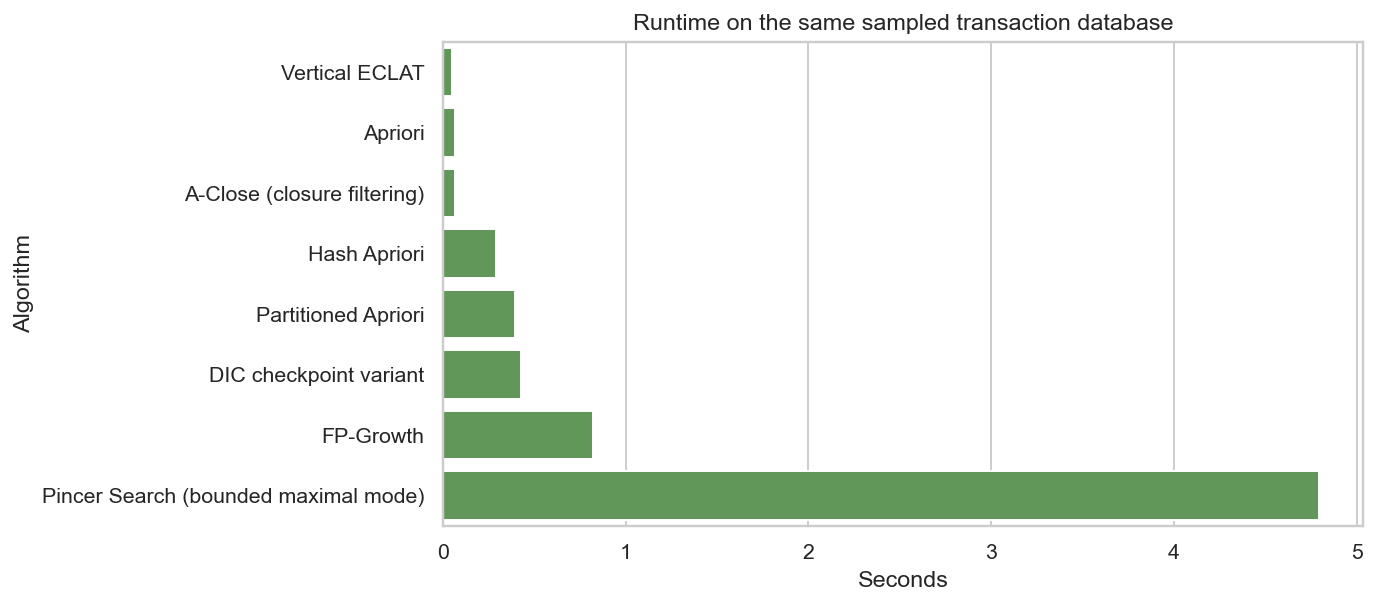

In [16]:
fig, ax = plt.subplots(figsize=(10, 4.5))
plot_data = benchmark.sort_values("runtime_seconds", ascending=True)
sns.barplot(data=plot_data, x="runtime_seconds", y="algorithm", ax=ax, color="#59A14F")
ax.set(title="Runtime on the same sampled transaction database", xlabel="Seconds", ylabel="Algorithm")
plt.tight_layout()
show_figure(fig)


### Algorithm comparison notes

- **Apriori** generates candidates level by level and uses the downward-closure property.
- **FP-Growth** compresses transactions into an FP-tree and mines conditional pattern bases.
- **Hash Apriori** uses pair-bucket counts to discard some 2-item candidates before exact counting.
- **Vertical ECLAT** intersects TID bitmaps and counts the resulting set bits.
- **Partitioned Apriori** mines each partition, unions local candidates, then verifies them globally.
- **DIC checkpoint variant** adds candidates at fixed data-prefix checkpoints and verifies support on the complete sample.
- **A-Close** returns closed sets by removing same-support subsets from the Apriori result.
- **Pincer-style maximal mode** tracks maximal frequent sets and a capped MFCS border while keeping the level-wise frontier for completeness up to `MAX_LEN`.

Candidate counts across FP-Growth, closure, and maximal modes are not perfectly like-for-like; interpret them together with the output-mode column. A-Close is run as closure filtering over Apriori's frequent sets, so its reported runtime includes both Apriori and the closure pass, and its independent candidate count is left blank.


## 5. High-lift rating patterns

Rules are generated from Apriori's complete frequent-set output so that each method's compressed output can be compared separately. The consequent must be one outcome item; outcome items are never allowed in the antecedent. Patterns are ranked by lift, with support count shown to discourage over-reading rare combinations.


In [17]:
rating_rules = pd.DataFrame(make_outcome_rules(
    mining_db,
    apriori_result["patterns"],
    min_confidence=0.0,
))
if not rating_rules.empty:
    high_rules = rating_rules.loc[
        rating_rules["consequent"].eq("OUTCOME::HighRating")
        & rating_rules["lift"].gt(1)
    ].sort_values(["lift", "support_count"], ascending=[False, False]).head(15).copy()
    high_rules["pattern"] = high_rules["antecedents"].apply(lambda items: " + ".join(items))
    high_rules["support_pct"] = (100 * high_rules["support"]).round(2)
    high_rules["confidence_pct"] = (100 * high_rules["confidence"]).round(1)
    high_rules["base_rate_pct"] = (100 * high_rules["base_rate"]).round(1)
    display(high_rules[["pattern", "support_count", "support_pct", "confidence_pct", "base_rate_pct", "lift"]].round({"lift": 2}))
else:
    high_rules = pd.DataFrame()
    print("No high-rating rules met the selected support threshold; lower support only with a clear caveat.")


,pattern,support_count,support_pct,confidence_pct,base_rate_pct,lift
270,GENRE::documentary + GENRE::music,1308,0.74,77.4,22.6,3.42
452,GENRE::documentary + KEYWORD::biography,485,0.27,73.2,22.6,3.24
303,GENRE::documentary + GENRE::tv movie,354,0.20,67.8,22.6,3.00
503,GENRE::documentary + KEYWORD::sports,278,0.16,66.5,22.6,2.94
408,GENRE::documentary + GENRE::history,620,0.35,66.0,22.6,2.92
687,GENRE::documentary + MONTH::11,1084,0.61,63.0,22.6,2.79
264,GENRE::documentary + KEYWORD::woman director,894,0.50,60.0,22.6,2.65
341,GENRE::documentary + MONTH::10,1143,0.64,59.7,22.6,2.64
504,GENRE::documentary + MONTH::09,1110,0.63,59.3,22.6,2.62
682,GENRE::documentary + MONTH::03,864,0.49,58.9,22.6,2.61


### Exploratory cast/director rules at a lower support threshold

Named cast and crew combinations occur less often than broad genres, so this supplementary table uses a lower support threshold and a maximum length of three. Treat these as exploratory patterns: lower support makes lift more sensitive to small counts, so the support count remains visible.


In [18]:
PEOPLE_MIN_SUPPORT = 0.0003
people_result = mine_apriori(mining_db, min_support=PEOPLE_MIN_SUPPORT, max_len=3)
people_rules = pd.DataFrame(make_outcome_rules(mining_db, people_result["patterns"]))
if not people_rules.empty:
    has_person = people_rules["antecedents"].apply(
        lambda items: any(item.startswith(("ACTOR::", "DIRECTOR::")) for item in items)
    )
    people_rules = people_rules.loc[
        has_person
        & people_rules["consequent"].eq("OUTCOME::HighRating")
        & people_rules["lift"].gt(1)
    ].sort_values(["lift", "support_count"], ascending=[False, False]).head(12).copy()
    if not people_rules.empty:
        people_rules["pattern"] = people_rules["antecedents"].apply(lambda items: " + ".join(items))
        people_rules["support_pct"] = (100 * people_rules["support"]).round(3)
        people_rules["confidence_pct"] = (100 * people_rules["confidence"]).round(1)
        people_rules["base_rate_pct"] = (100 * people_rules["base_rate"]).round(1)
        display(people_rules[["pattern", "support_count", "support_pct", "confidence_pct", "base_rate_pct", "lift"]].round({"lift": 2}))
    else:
        print("No cast/director rule exceeded lift 1 at this support threshold.")
else:
    print("No cast/director rule met the exploratory support threshold.")


,pattern,support_count,support_pct,confidence_pct,base_rate_pct,lift
490,DIRECTOR::joseph barbera + GENRE::comedy,91,0.051,82.0,22.6,3.63
1945,DIRECTOR::william hanna + GENRE::comedy,91,0.051,81.2,22.6,3.60
882,DIRECTOR::joseph barbera + DIRECTOR::william hanna,108,0.061,77.1,22.6,3.41
1319,DIRECTOR::joseph barbera + GENRE::animation,106,0.060,76.3,22.6,3.38
1373,DIRECTOR::william hanna + GENRE::animation,107,0.060,75.9,22.6,3.36
88,DIRECTOR::william hanna,109,0.061,75.7,22.6,3.35
32,DIRECTOR::joseph barbera,108,0.061,75.5,22.6,3.34
438,ACTOR::larry fine + ACTOR::moe howard,147,0.083,72.4,22.6,3.20
149,ACTOR::larry fine,147,0.083,72.1,22.6,3.19
322,ACTOR::larry fine + GENRE::comedy,147,0.083,72.1,22.6,3.19


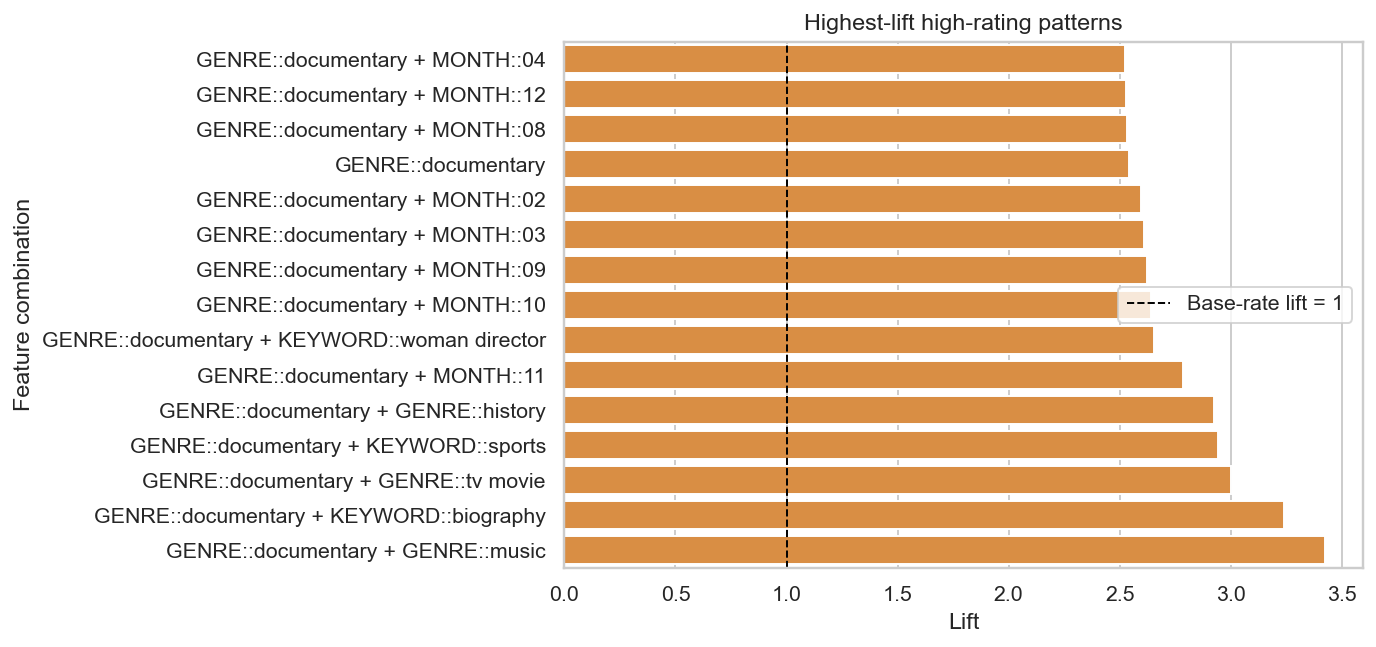

In [19]:
if not high_rules.empty:
    chart = high_rules.sort_values("lift", ascending=True)
    fig, ax = plt.subplots(figsize=(10, max(4, 0.32 * len(chart))))
    sns.barplot(data=chart, x="lift", y="pattern", ax=ax, color="#F28E2B")
    ax.axvline(1, color="black", linestyle="--", linewidth=1, label="Base-rate lift = 1")
    ax.set(title="Highest-lift high-rating patterns", xlabel="Lift", ylabel="Feature combination")
    ax.legend()
    plt.tight_layout()
    show_figure(fig)


## 6. Box-office association rules

Only titles with positive budget and revenue are eligible. Missing financial outcomes are not treated as negative examples. The label `revenue > budget` is presented as a revenue-to-budget proxy, not as audited profitability.


In [20]:
box_baskets = outcome_baskets(box_data, "box_hit", "RevenueAboveBudget", "RevenueAtOrBelowBudget")
box_counts = Counter(item for basket in box_baskets for item in basket)
box_vocabulary = set()
for prefix, limit in category_limits.items():
    category_items = [item for item in box_counts if item.startswith(prefix)]
    if prefix in {"GENRE::", "MONTH::"}:
        box_vocabulary.update(category_items)
    else:
        box_vocabulary.update(sorted(category_items, key=lambda item: (-box_counts[item], item))[:limit])
box_vocabulary.update(item for item in box_counts if item.startswith("OUTCOME::"))
box_db = VerticalTransactionDB([sorted(set(basket) & box_vocabulary) for basket in box_baskets])
BOX_MIN_SUPPORT = 0.005
box_apriori = mine_apriori(box_db, min_support=BOX_MIN_SUPPORT, max_len=4)
box_rules = pd.DataFrame(make_outcome_rules(box_db, box_apriori["patterns"]))
if not box_rules.empty:
    box_hits = box_rules.loc[
        box_rules["consequent"].eq("OUTCOME::RevenueAboveBudget")
        & box_rules["lift"].gt(1)
    ].sort_values(["lift", "support_count"], ascending=[False, False]).head(12).copy()
    box_hits["pattern"] = box_hits["antecedents"].apply(lambda items: " + ".join(items))
    box_hits["support_pct"] = (100 * box_hits["support"]).round(2)
    box_hits["confidence_pct"] = (100 * box_hits["confidence"]).round(1)
    box_hits["base_rate_pct"] = (100 * box_hits["base_rate"]).round(1)
    display(box_hits[["pattern", "support_count", "support_pct", "confidence_pct", "base_rate_pct", "lift"]].round({"lift": 2}))
else:
    box_hits = pd.DataFrame()
    print("No revenue-to-budget rules met the selected support threshold.")


,pattern,support_count,support_pct,confidence_pct,base_rate_pct,lift
654,GENRE::horror + GENRE::thriller + KEYWORD::sequel,52,0.51,96.3,65.1,1.48
253,GENRE::thriller + KEYWORD::sequel,98,0.97,94.2,65.1,1.45
293,GENRE::horror + KEYWORD::sequel,87,0.86,92.6,65.1,1.42
546,GENRE::adventure + GENRE::science fiction + MONTH::06,53,0.52,91.4,65.1,1.40
485,GENRE::action + KEYWORD::sequel,121,1.20,91.0,65.1,1.40
105,KEYWORD::sequel,283,2.80,89.6,65.1,1.38
378,GENRE::action + KEYWORD::duringcreditsstinger,64,0.63,88.9,65.1,1.37
430,GENRE::family + KEYWORD::sequel,55,0.54,88.7,65.1,1.36
244,GENRE::adventure + KEYWORD::duringcreditsstinger,67,0.66,88.2,65.1,1.35
673,GENRE::comedy + GENRE::family + MONTH::11,52,0.51,88.1,65.1,1.35


## 7. Decision tree and Naive Bayes classification

The classifiers use the same pre-release features as the mining analysis. IMDb/TMDB ratings, vote counts, popularity, revenue, and the target label are excluded from predictors. The feature vocabulary is limited to the 3,000 most frequent typed items to control sparsity. Both targets are evaluated separately; the box-office classifier uses only the financially complete subset.


In [21]:
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, confusion_matrix,
)

def encode_frame(frame, max_features=3000, min_document_frequency=30):
    baskets = feature_baskets(frame)
    counts = Counter(item for basket in baskets for item in basket)
    vocabulary = [
        item for item, count in sorted(counts.items(), key=lambda pair: (-pair[1], pair[0]))
        if count >= min_document_frequency
    ][:max_features]
    vocabulary_set = set(vocabulary)
    filtered = [[item for item in basket if item in vocabulary_set] for basket in baskets]
    encoder = MultiLabelBinarizer(classes=vocabulary, sparse_output=True)
    X = encoder.fit_transform(filtered).tocsr()
    return X, encoder.classes_, len(vocabulary)

def evaluate_classifiers(frame, target, task_name):
    X, feature_names, feature_count = encode_frame(frame)
    y = frame[target].astype(int).to_numpy()
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
    )
    models = {
        "Decision Tree": DecisionTreeClassifier(
            criterion="gini", max_depth=12, min_samples_leaf=20,
            class_weight="balanced", random_state=RANDOM_SEED,
        ),
        "Bernoulli Naive Bayes": BernoulliNB(alpha=1.0),
    }
    result_rows = []
    matrices = {}
    for model_name, model in models.items():
        model.fit(X_train, y_train)
        prediction = model.predict(X_test)
        probability = model.predict_proba(X_test)[:, 1]
        result_rows.append({
            "task": task_name,
            "model": model_name,
            "test_rows": len(y_test),
            "features": feature_count,
            "accuracy": accuracy_score(y_test, prediction),
            "balanced_accuracy": balanced_accuracy_score(y_test, prediction),
            "precision": precision_score(y_test, prediction, zero_division=0),
            "recall": recall_score(y_test, prediction, zero_division=0),
            "f1": f1_score(y_test, prediction, zero_division=0),
            "roc_auc": roc_auc_score(y_test, probability),
            "pr_auc": average_precision_score(y_test, probability),
        })
        matrices[(task_name, model_name)] = confusion_matrix(y_test, prediction)
    return result_rows, matrices

rating_metrics, rating_matrices = evaluate_classifiers(rating_data, "high_rating", "High rating")
box_metrics, box_matrices = evaluate_classifiers(box_data, "box_hit", "Revenue > budget")
classifier_metrics = pd.DataFrame(rating_metrics + box_metrics)
display(classifier_metrics.round(3))


,task,model,test_rows,features,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc
0,High rating,Decision Tree,35454,3000,0.629,0.663,0.347,0.726,0.469,0.737,0.458
1,High rating,Bernoulli Naive Bayes,35454,3000,0.789,0.659,0.544,0.421,0.474,0.764,0.495
2,Revenue > budget,Decision Tree,2024,408,0.570,0.566,0.708,0.577,0.636,0.598,0.723
3,Revenue > budget,Bernoulli Naive Bayes,2024,408,0.633,0.586,0.708,0.743,0.725,0.642,0.757


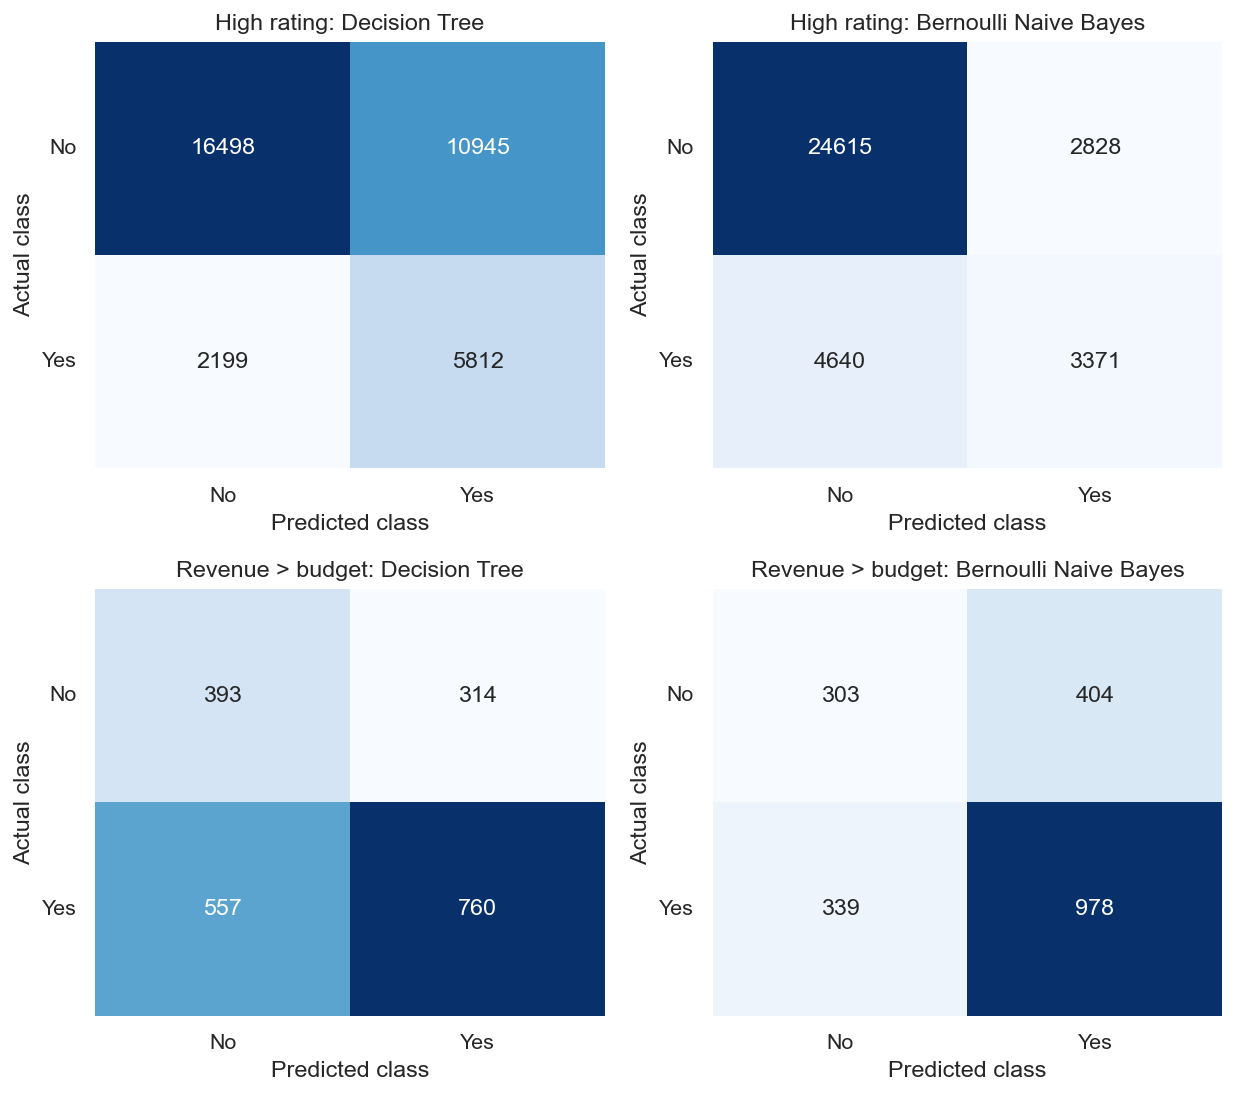

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for ax, ((task_name, model_name), matrix) in zip(axes.flat, list(rating_matrices.items()) + list(box_matrices.items())):
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set(title=f"{task_name}: {model_name}", xlabel="Predicted class", ylabel="Actual class")
    ax.set_xticklabels(["No", "Yes"])
    ax.set_yticklabels(["No", "Yes"], rotation=0)
plt.tight_layout()
show_figure(fig)


### Classifier interpretation

Accuracy is reported alongside balanced accuracy, precision, recall, F1, ROC-AUC, and PR-AUC. This avoids relying on accuracy alone when positive and negative classes differ in size. The decision tree is constrained to depth 12 with a minimum leaf size of 20; Bernoulli Naive Bayes uses Laplace smoothing (`alpha=1`). Results are a random stratified holdout estimate, not evidence of future-time generalization.


## 8. Findings, limitations, and next steps

Use the generated tables and charts to write the final interpretation. Discuss the strongest patterns with their support counts and lifts, compare algorithm runtime/output modes, and compare classifier metrics. Avoid describing an association as causal.

**Limitations:** the merged data has repeated source IDs and substantial missing keywords; cast and genre are incomplete too. The box-office subset is much smaller than the overall file, and revenue exceeding budget is not net profit. The data spans many release eras without inflation adjustment. Results depend on the chosen support threshold, cast/keyword truncation, sample size, and success definitions.

**Reproducibility:** run the notebook from top to bottom with the CSV and `movie_mining.py` beside it. The classifier split and model settings are fixed by seed 42. Before submission, add team details, confirm the topic is unique, save the executed notebook with outputs, and include the accompanying report and source module.
